# Stress-Test Tornado Chart

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

For each risk factor, a horizontal bar runs from the portfolio's P&L under a downside shock to its P&L under an upside shock. Bars are sorted by total range, so the widest (most important) sensitivities sit at the top and the chart narrows like a tornado. It ranks which assumptions matter most.

## When to use

- Rank the sensitivity of a portfolio, valuation or budget to individual assumptions
- Communicate scenario or stress-test results to non-specialists
- Decide which inputs deserve more research or hedging

## Avoid when

- Factors interact strongly (one-at-a-time shocks mislead; use joint scenarios)
- Shocks are not comparable in likelihood (state the shock size for each bar)

## Alternatives

- Scenario table with joint shocks
- DCF / two-way sensitivity table
- Waterfall from base case to stressed case

## Design tips

- Label each bar end with the shock used (e.g. "equities −20%")
- Use the same diverging colors for loss and gain throughout
- Draw the base case as a vertical zero line

## Example

Simulated one-at-a-time shocks to a 100 million multi-asset portfolio (P&L in millions). Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({
    "factor":   ["Equity markets", "Interest rates", "Credit spreads", "USD exchange rate",
                 "Oil price", "Inflation", "Equity volatility", "Real estate"],
    "down_shock": ["−20%", "+100 bp", "+150 bp", "USD +10%", "−30%", "+2 pp", "VIX +15", "−15%"],
    "up_shock":   ["+20%", "−100 bp", "−75 bp", "USD −10%", "+30%", "−1 pp", "VIX −5", "+15%"],
    "down_pnl": [-11.8, -4.6, -3.9, -2.4, -1.1, -1.6, -2.9, -1.4],   # P&L, $ millions
    "up_pnl":   [10.9, 4.1, 1.8, 2.2, 0.9, 0.7, 0.8, 1.3],
})
df["range"] = df["up_pnl"] - df["down_pnl"]
df = df.sort_values("range").reset_index(drop=True)
df

,factor,down_shock,up_shock,down_pnl,up_pnl,range
0,Oil price,−30%,+30%,-1.1,0.9,2.0
1,Inflation,+2 pp,−1 pp,-1.6,0.7,2.3
2,Real estate,−15%,+15%,-1.4,1.3,2.7
3,Equity volatility,VIX +15,VIX −5,-2.9,0.8,3.7
4,USD exchange rate,USD +10%,USD −10%,-2.4,2.2,4.6
5,Credit spreads,+150 bp,−75 bp,-3.9,1.8,5.7
6,Interest rates,+100 bp,−100 bp,-4.6,4.1,8.7
7,Equity markets,−20%,+20%,-11.8,10.9,22.7


### Plot

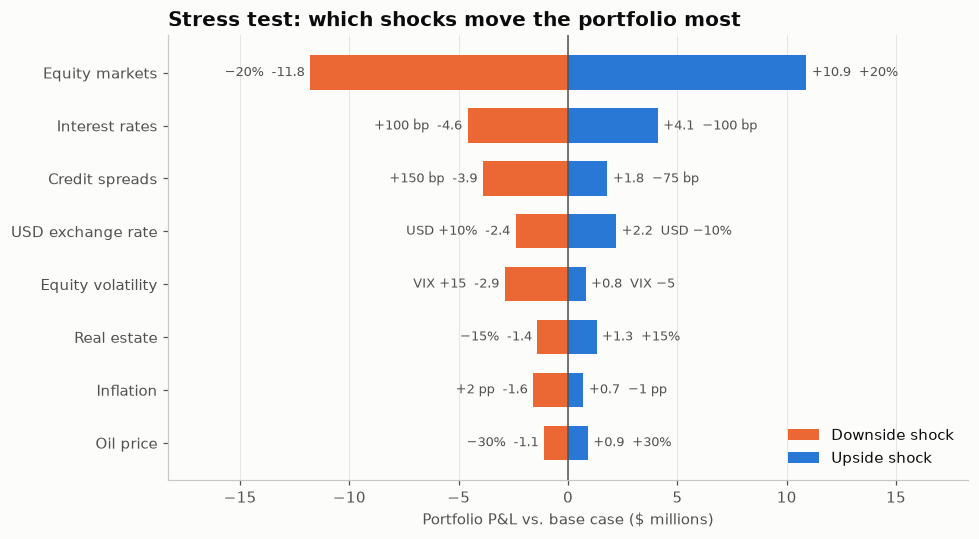

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(df))
ax.barh(y, df["down_pnl"], color=PALETTE[1], height=0.65, label="Downside shock")
ax.barh(y, df["up_pnl"], color=PALETTE[0], height=0.65, label="Upside shock")
for yi, row in df.iterrows():
    ax.text(row["down_pnl"] - 0.25, yi, f"{row['down_shock']}  {row['down_pnl']:+.1f}", ha="right",
            va="center", fontsize=8.5, color="#52514e")
    ax.text(row["up_pnl"] + 0.25, yi, f"{row['up_pnl']:+.1f}  {row['up_shock']}", ha="left",
            va="center", fontsize=8.5, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, df["factor"])
lim = df[["down_pnl", "up_pnl"]].abs().max().max() * 1.55
ax.set_xlim(-lim, lim)
ax.set_xlabel("Portfolio P&L vs. base case ($ millions)")
ax.set_title("Stress test: which shocks move the portfolio most")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

Each row is one factor. Orange extends to the loss under the downside shock and blue to the gain under the upside shock. Equity markets dominate; inflation and FX matter far less for this portfolio.

---
Standalone script: [`stress_test_tornado.py`](stress_test_tornado.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)